# Tarea - escalamiento y transformación

En el archivo `Escalamiento.xlsx` hay dos variables, $x_1$ y $x_2$: on Sheet `1`

- $x_1$ - red neuronal con activación **sigmoidal unipolar** (salida en $(0,1)$).
- $x_2$ - red neuronal con activación **tangente hiperbólica** (salida en $(-1,1)$).

**Plan**
1. Transformar cada variable con una función de potencia (Box-Cox) para acercarla a una distribución Normal.
2. Escalar cada variable al rango de su función de activación.

In [2]:
!pip install matplotlib

  Using cached matplotlib-3.11.2-cp311-cp311-win_amd64.whl.metadata (80 kB)
  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.68.0-cp311-cp311-win_amd64.whl.metadata (142 kB)
  Using cached kiwisolver-1.5.1-cp311-cp311-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp311-cp311-win_amd64.whl (9.3 MB)
Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl (225 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.68.0-cp311-cp311-win_amd64.whl (1.7 MB)
Using cached kiwisolver-1.5.1-cp311-cp311-win_amd64.whl (70 kB)
Using cached pillow-13.0.0-cp311-cp311-win_amd64.whl (7.3 MB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)

   ---------------------------------------- 0/7 [pyparsing]
   -


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
!pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import boxcox, shapiro, skew, kurtosis

## 0. Cargar los datos

In [6]:
df = pd.read_excel('Escalamiento.xlsx', sheet_name='Hoja1')
print(df.shape)
print('Valores nulos:\n', df.isna().sum())
print('Valores <= 0:\n', (df <= 0).sum())
df.describe()

(3287, 2)
Valores nulos:
 x1    0
x2    0
dtype: int64
Valores <= 0:
 x1    0
x2    0
dtype: int64


,x1,x2
count,3.287000e+03,3.287000e+03
mean,3.215457e+07,1.457638e+07
std,3.948668e+07,2.910075e+07
min,3.000000e+04,1.040135e+04
25%,6.170000e+06,3.915000e+06
50%,1.612000e+07,7.950000e+06
75%,4.411500e+07,1.552500e+07
max,2.999200e+08,5.490700e+08


Todos los valores son **estrictamente positivos**, así que se puede usar Box-Cox (que exige $x>0$):

$$
x^{(\lambda)}=\begin{cases}\dfrac{x^{\lambda}-1}{\lambda}, & \lambda\neq 0\\[2mm] \ln x, & \lambda=0\end{cases}
$$

El valor de $\lambda$ se elige por **máxima verosimilitud**, es decir, el que maximiza la probabilidad de que los datos transformados sean Normales.

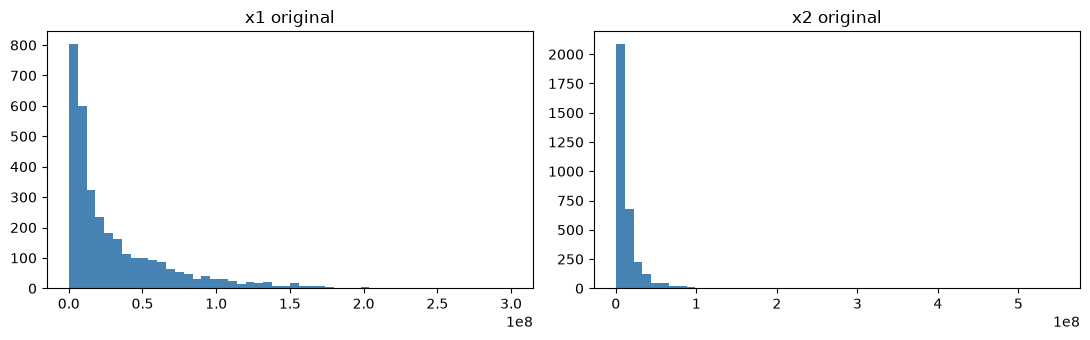

,variable,media,mediana,asimetria,curtosis_exceso,Shapiro p-valor
0,x1,3.215457e+07,16120000.0,2.334016,7.207671,3.678978e-58
1,x2,1.457638e+07,7950000.0,10.560362,160.311456,2.183575e-75


In [7]:
def resumen(x, nombre):
    return {'variable': nombre, 'media': x.mean(), 'mediana': np.median(x),
            'asimetria': skew(x), 'curtosis_exceso': kurtosis(x),
            'Shapiro p-valor': shapiro(x)[1]}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, c in zip(ax, ['x1', 'x2']):
    a.hist(df[c], bins=50, color='steelblue'); a.set_title(f'{c} original')
plt.tight_layout(); plt.show()

pd.DataFrame([resumen(df[c], c) for c in ['x1', 'x2']])

Ambas variables están muy **sesgadas a la derecha** (asimetría positiva grande, cola larga). Por eso la transformación es necesaria.

## 1. Transformación de potencia (Box-Cox)

In [8]:
x1_bc, lam1 = boxcox(df['x1'])
x2_bc, lam2 = boxcox(df['x2'])
print(f'lambda x1 = {lam1:.4f}')
print(f'lambda x2 = {lam2:.4f}')

lambda x1 = 0.0885
lambda x2 = 0.1584


Ahora se ve la **curva de verosimilitud** para confirmar que ese $\lambda$ es el máximo, y se compara antes/después con histogramas y gráficas Q-Q.

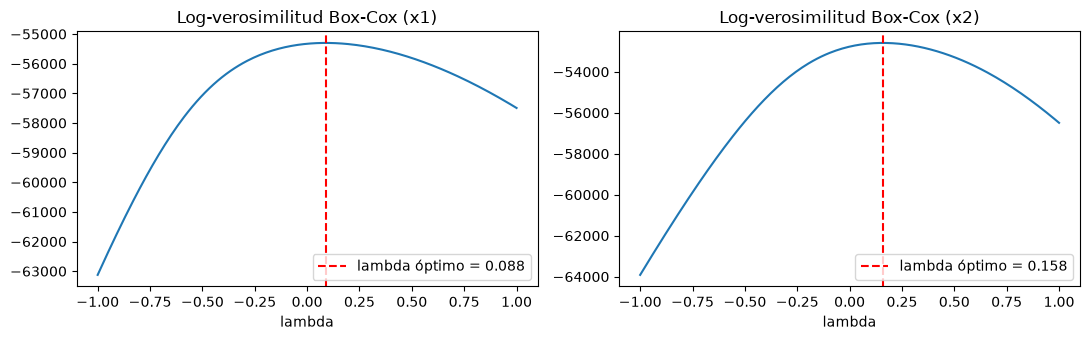

In [9]:
lams = np.linspace(-1, 1, 200)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, c, lam in zip(ax, ['x1', 'x2'], [lam1, lam2]):
    ll = [stats.boxcox_llf(l, df[c]) for l in lams]
    a.plot(lams, ll); a.axvline(lam, color='r', ls='--', label=f'lambda óptimo = {lam:.3f}')
    a.set_title(f'Log-verosimilitud Box-Cox ({c})'); a.set_xlabel('lambda'); a.legend()
plt.tight_layout(); plt.show()

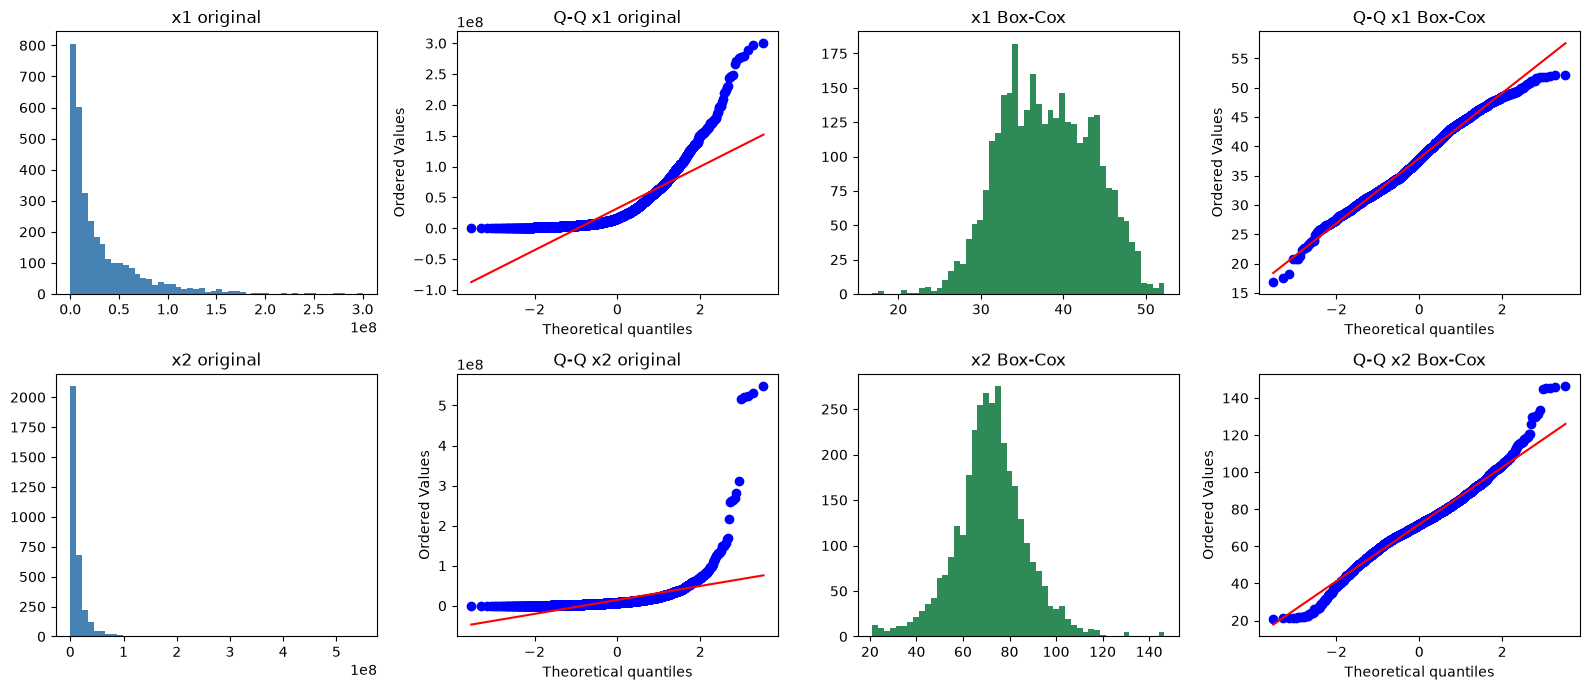

,variable,media,mediana,asimetria,curtosis_exceso,Shapiro p-valor
0,x1 original,3.215457e+07,1.612000e+07,2.334016,7.207671,3.678978e-58
1,x1 Box-Cox,3.798715e+01,3.777185e+01,-0.017022,-0.491533,6.734692e-13
2,x2 original,1.457638e+07,7.950000e+06,10.560362,160.311456,2.183575e-75
3,x2 Box-Cox,7.189500e+01,7.186605e+01,0.097564,1.602898,1.108279e-19


In [10]:
fig, ax = plt.subplots(2, 4, figsize=(16, 7))
datos = {'x1': (df['x1'], x1_bc), 'x2': (df['x2'], x2_bc)}
for i, (c, (orig, trans)) in enumerate(datos.items()):
    ax[i,0].hist(orig, bins=50, color='steelblue');  ax[i,0].set_title(f'{c} original')
    stats.probplot(orig, dist='norm', plot=ax[i,1]);  ax[i,1].set_title(f'Q-Q {c} original')
    ax[i,2].hist(trans, bins=50, color='seagreen');  ax[i,2].set_title(f'{c} Box-Cox')
    stats.probplot(trans, dist='norm', plot=ax[i,3]); ax[i,3].set_title(f'Q-Q {c} Box-Cox')
plt.tight_layout(); plt.show()

pd.DataFrame([resumen(df['x1'],'x1 original'), resumen(x1_bc,'x1 Box-Cox'),
              resumen(df['x2'],'x2 original'), resumen(x2_bc,'x2 Box-Cox')])

**Lectura:** después de Box-Cox la asimetría baja casi a cero y los puntos del Q-Q siguen la recta. Con $n\approx 3300$ la prueba de Shapiro-Wilk es muy sensible, así que un p-valor pequeño puede aparecer por desviaciones mínimas; lo importante es la mejora enorme en forma y asimetría.

## 2. Escalamiento al rango de cada función de activación

Se usa **min-max** sobre los datos ya transformados (Box-Cox conserva el orden, es monótona):

$$
x_{esc}=a+(b-a)\,\frac{x^{(\lambda)}-\min}{\max-\min}
$$

| Variable | Activación | Rango de salida | Rango de escalamiento $[a,b]$ |
|---|---|---|---|
| $x_1$ | Sigmoide unipolar $\dfrac{1}{1+e^{-z}}$ | $(0,1)$ | $[0.1,\,0.9]$ |
| $x_2$ | Tangente hiperbólica | $(-1,1)$ | $[-0.9,\,0.9]$ |

Se usan $0.1$–$0.9$ en lugar de $0$–$1$ porque las funciones solo **tocan** sus extremos en $\pm\infty$: un objetivo de exactamente 0 o 1 (o $\pm1$) satura la neurona y la derivada tiende a 0, lo que frena el aprendizaje.

In [11]:
def minmax(x, a, b):
    xmin, xmax = x.min(), x.max()
    return a + (b - a) * (x - xmin) / (xmax - xmin), xmin, xmax

x1_esc, x1_min, x1_max = minmax(x1_bc, 0.1, 0.9)    # sigmoide unipolar
x2_esc, x2_min, x2_max = minmax(x2_bc, -0.9, 0.9)   # tangente hiperbólica

print(f'x1 escalada: min={x1_esc.min():.2f}, max={x1_esc.max():.2f}')
print(f'x2 escalada: min={x2_esc.min():.2f}, max={x2_esc.max():.2f}')

x1 escalada: min=0.10, max=0.90
x2 escalada: min=-0.90, max=0.90


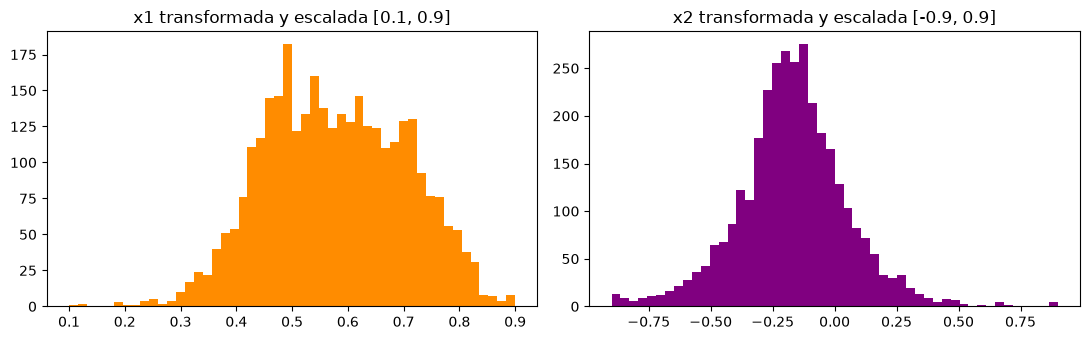

In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(x1_esc, bins=50, color='darkorange'); ax[0].set_title('x1 transformada y escalada [0.1, 0.9]')
ax[1].hist(x2_esc, bins=50, color='purple');     ax[1].set_title('x2 transformada y escalada [-0.9, 0.9]')
plt.tight_layout(); plt.show()

## 3. Resultado final y funciones inversas
Se guardan los parámetros para regresar las predicciones de la red a la escala original.

In [13]:
from scipy.special import inv_boxcox

resultado = pd.DataFrame({'x1': df['x1'], 'x2': df['x2'],
                          'x1_escalada': x1_esc, 'x2_escalada': x2_esc})
display(resultado.head())

params = {'x1': dict(lam=lam1, min=x1_min, max=x1_max, a=0.1,  b=0.9),
          'x2': dict(lam=lam2, min=x2_min, max=x2_max, a=-0.9, b=0.9)}
print(params)

def destransformar(y_esc, p):
    """Escala de la red -> unidades originales."""
    bc = p['min'] + (np.asarray(y_esc) - p['a']) * (p['max'] - p['min']) / (p['b'] - p['a'])
    return inv_boxcox(bc, p['lam'])

# Comprobación: se recupera el dato original
print(np.allclose(destransformar(x1_esc, params['x1']), df['x1']),
      np.allclose(destransformar(x2_esc, params['x2']), df['x2']))

,x1,x2,x1_escalada,x2_escalada
0,6050000.0,5390000.0,0.480786,-0.237810
1,4720000.0,700000.0,0.458708,-0.528890
2,4460000.0,10140000.0,0.453737,-0.126889
3,34740000.0,6600000.0,0.650747,-0.203463
4,1910000.0,3390000.0,0.382230,-0.312426


{'x1': {'lam': np.float64(0.08847635044758351), 'min': np.float64(16.835474919704563), 'max': np.float64(52.258044340225), 'a': 0.1, 'b': 0.9}, 'x2': {'lam': np.float64(0.15836076304890076), 'min': np.float64(21.006633346646655), 'max': np.float64(146.570885512863), 'a': -0.9, 'b': 0.9}}
True True


## Conclusiones

- Se aplicó **Box-Cox** a $x_1$ y a $x_2$ con $\lambda$ por máxima verosimilitud; ambas pasaron de distribuciones muy sesgadas a formas casi simétricas.
- $x_1$ se escaló a $[0.1,0.9]$ (sigmoide unipolar, salida en $(0,1)$) y $x_2$ a $[-0.9,0.9]$ (tanh, salida en $(-1,1)$).
- Los parámetros ($\lambda$, mínimo, máximo) se guardaron para invertir el proceso en las predicciones.